# One model for all commodities
### Pooled machine learning against single-market models for volatility forecasting, with walk-forward evidence on 30 commodity markets (2001-2026)

## 1. Introduction

Volatility forecasts are used for risk targeting, margins and option prices. Two recent papers study stocks
(Zhang, Zhang, Cucuringu & Qian 2024; Christensen, Siggaard & Veliyev 2023) and find that a machine-learning model
trained on many stocks at once forecasts volatility better than HAR. We test whether this also holds for commodities.
Commodities have far fewer markets than stocks, and these markets have less in common.

HAR (Corsi 2009) is one of the standard volatility models. It is a linear regression of next month's volatility on past
volatility, fitted to each market separately. We ask if one model trained on 30 commodity markets at once can do
better. One market only has a few volatility episodes, but 30 markets together have many more.

We compare pooled models (linear, boosted trees, neural network) with models fitted to each market, in a walk-forward
from 2001 to 2026. Features, architectures and grids were selected on 2001-2020.

Over 2001-2020 the pooled network beats each market's own HAR in 80 % of markets, and in the median market its MSE is
10 % lower. Over 2021-2026 it still wins in 73 % of markets (sign test p = 0.008), with an MSE 4 % lower in the median
market. Pooling is needed, since the same trees fitted to each market lose to HAR in 90 % of markets. After 2020 the
pooled model also has to be nonlinear. The pooled linear model no longer beats HAR (43 % of markets), while the pooled
network still does (73 %).

The rule the network learns is simple. After a volatility spike, the larger the price move, the more of the spike is
still there a month later. The raw data show the same pattern, and the network follows it while HAR does not. The value
of the forecasts is in risk control and not in return, as the Sharpe ratio of a risk-targeted portfolio does not change.

### Setup

The saved outputs come from data downloaded in November 2026 (data fingerprint `a256d0eced8df3d6`, printed in §2).
A fresh download gives a different fingerprint and can move some results by a few points.

In [1]:
import subprocess
import sys
from importlib.metadata import version
from importlib.util import find_spec

packages = {
    "sklearn": "scikit-learn",
    "statsmodels": "statsmodels",
    "matplotlib": "matplotlib",
    "requests": "requests",
    "pyarrow": "pyarrow",
    "xlrd": "xlrd",
    "cvxpy": "cvxpy",
    "yfinance": "yfinance",
}
missing = [name for module, name in packages.items() if find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

from packaging.version import Version

if Version(version("yfinance")) < Version("0.2.58"):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "yfinance"])
if find_spec("skfin") is None:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/schampon/skfin.git"]
    )

import hashlib
import io
import os
import time
import warnings
from dataclasses import dataclass
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import sklearn
import statsmodels.api as sm
import yfinance as yf
from joblib import Parallel, delayed
from scipy.stats import binomtest, jarque_bera, kurtosis, skew
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from skfin.backtesting import compute_pnl, fit_predict
from skfin.backtesting_with_cost import average_holding_period
from skfin.metrics import sharpe_ratio
from skfin.plot import bar, line

pd.set_option("display.width", 200)

CACHE_DIR = Path("data/cache")
FORCE_RELOAD = False
FORCE_RECOMPUTE = False
FAST = False
END = "2026-10-01"
H = 21
GAP = pd.Timedelta(days=2 * H)
FIRST, LAST, STEP = 2001, 2025, 2
START_OOS = 2021
SEEDS = range(2) if FAST else range(10)
OIL = "WTI futures"
RISK_TARGET, CAP, COST = 0.10, 5.0, 2e-4
start_time = time.time()
print(
    "python",
    sys.version.split()[0],
    "| numpy",
    np.__version__,
    "| pandas",
    pd.__version__,
    "| scikit-learn",
    sklearn.__version__,
    "| FAST:",
    FAST,
)

python 3.13.7 | numpy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1 | FAST: False


## 2. Dataset overview

We use 24 futures from Yahoo Finance (continuous front month, starting between 1997 and 2007), covering energy, metals,
grains, softs and livestock. We add 6 spot prices from the EIA (from 1990) for crude oil, refined products and Henry Hub
gas, which gives a longer energy history. Henry Hub only starts in 2012, because before that the EIA file has gaps of
several weeks that would count as one-day returns.

Daily log returns are clipped at ±25 %, and stale quotes (price unchanged for 5 days or more) are removed. We also
remove roll days. When a continuous future switches contract, the "return" of that day includes the price gap between
two contracts. The public expiry rule of each exchange tells us which day to drop.

In [2]:
EIA_SPOT = {
    "WTI spot": ("RWTCd", "pet"),
    "Brent spot": ("RBRTEd", "pet"),
    "Gasoline NYH": ("EER_EPMRU_PF4_Y35NY_DPGd", "pet"),
    "Heating oil NYH": ("EER_EPD2F_PF4_Y35NY_DPGd", "pet"),
    "Jet fuel Gulf": ("EER_EPJK_PF4_RGC_DPGd", "pet"),
    "Henry Hub gas": ("RNGWHHDd", "ng"),
}
YAHOO = {
    "CL=F": "WTI futures",
    "BZ=F": "Brent futures",
    "NG=F": "Natural gas futures",
    "RB=F": "RBOB gasoline futures",
    "HO=F": "Heating oil futures",
    "GC=F": "Gold",
    "SI=F": "Silver",
    "HG=F": "Copper",
    "PL=F": "Platinum",
    "PA=F": "Palladium",
    "ZC=F": "Corn",
    "ZW=F": "Wheat (Chicago)",
    "KE=F": "Wheat (Kansas City)",
    "ZS=F": "Soybeans",
    "ZL=F": "Soybean oil",
    "ZM=F": "Soybean meal",
    "ZR=F": "Rough rice",
    "CT=F": "Cotton",
    "KC=F": "Coffee",
    "CC=F": "Cocoa",
    "SB=F": "Sugar",
    "LE=F": "Live cattle",
    "GF=F": "Feeder cattle",
    "HE=F": "Lean hogs",
}
CLASSES = {
    "Crude oil": ["WTI futures", "Brent futures", "WTI spot", "Brent spot"],
    "Refined products & gas": [
        "RBOB gasoline futures",
        "Heating oil futures",
        "Natural gas futures",
        "Gasoline NYH",
        "Heating oil NYH",
        "Jet fuel Gulf",
        "Henry Hub gas",
    ],
    "Metals": ["Gold", "Silver", "Copper", "Platinum", "Palladium"],
    "Grains & oilseeds": [
        "Corn",
        "Wheat (Chicago)",
        "Wheat (Kansas City)",
        "Soybeans",
        "Soybean oil",
        "Soybean meal",
        "Rough rice",
    ],
    "Softs": ["Cotton", "Coffee", "Cocoa", "Sugar"],
    "Livestock": ["Live cattle", "Feeder cattle", "Lean hogs"],
}
ASSET_CLASS = {asset: c for c, assets in CLASSES.items() for asset in assets}
FUTURES = list(YAHOO.values())

ROLL_RULES = {
    "WTI futures": "cme_wti",
    "Brent futures": [("start", 1), ("start", 2)],
    "Natural gas futures": [("end", 2)],
    "RBOB gasoline futures": [("start", 1)],
    "Heating oil futures": [("start", 1)],
    "Gold": [("start", 1)],
    "Silver": [("start", 1)],
    "Copper": [("start", 1)],
    "Platinum": [("start", 1)],
    "Palladium": [("start", 1)],
    "Corn": "day15",
    "Wheat (Chicago)": "day15",
    "Wheat (Kansas City)": "day15",
    "Soybeans": "day15",
    "Soybean oil": "day15",
    "Soybean meal": "day15",
    "Rough rice": "day15",
    "Cotton": [("end", 16)],
    "Coffee": [("end", 8)],
    "Cocoa": [("end", 11)],
    "Sugar": [("start", 1)],
    "Live cattle": [("start", 1)],
    "Feeder cattle": [("start", 1)],
    "Lean hogs": [("start", 11)],
}


def download(url):
    for attempt in range(5):
        try:
            response = requests.get(
                url,
                timeout=120,
                headers={"User-Agent": "Mozilla/5.0"},
            )
            response.raise_for_status()
            return response
        except requests.RequestException:
            if attempt == 4:
                raise
            time.sleep(2**attempt)


def load_eia(key, area):
    url = f"https://www.eia.gov/dnav/{area}/hist_xls/{key}.xls"
    raw = pd.read_excel(
        io.BytesIO(download(url).content), sheet_name="Data 1", header=None, skiprows=3
    )
    prices = pd.to_numeric(raw[1], errors="coerce").to_numpy()
    return pd.Series(prices, index=pd.to_datetime(raw[0])).dropna().sort_index()


def load_yahoo():
    data = yf.download(
        list(YAHOO),
        start="1985-01-01",
        end=END,
        auto_adjust=True,
        actions=True,
        progress=False,
    )
    prices = data["Close"].rename(columns=YAHOO).reindex(columns=FUTURES)
    empty = prices.columns[prices.count() == 0].tolist()
    if empty:
        raise RuntimeError(f"yfinance returned no prices for {empty}")
    return prices.sort_index()


def load_cached(name, load):
    path = CACHE_DIR / f"{name}.parquet"
    if path.exists() and not FORCE_RELOAD:
        return pd.read_parquet(path)
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    df = load()
    df.columns = [str(c) for c in df.columns]
    df.index.name = "date"
    df.to_parquet(path)
    return df


eia_spot = load_cached(
    "eia_spot", lambda: pd.concat({k: load_eia(*v) for k, v in EIA_SPOT.items()}, axis=1)
)
yahoo = load_cached("yahoo", load_yahoo)
eia_spot, yahoo = eia_spot[eia_spot.index < END], yahoo[yahoo.index < END]
henry_hub = eia_spot["Henry Hub gas"].where(eia_spot.index >= "2012")
eia_spot = eia_spot.assign(**{"Henry Hub gas": henry_hub}).dropna(how="all")
all_prices = pd.concat([eia_spot, yahoo], axis=1).round(4).to_numpy()
fingerprint = hashlib.sha256(all_prices.tobytes()).hexdigest()[:16]


def wti_last_trading_days(dates):
    out = []
    for year, month in sorted({(d.year, d.month) for d in dates}):
        day_25 = pd.Timestamp(year, month, 25)
        before = dates[dates < day_25]
        if len(before) >= 4 and day_25 <= dates[-1]:
            out.append(before[-3] if day_25 in dates else before[-4])
    return pd.DatetimeIndex(out)


def switch_days(dates, rule):
    dates = pd.DatetimeIndex(sorted(dates))
    if rule == "cme_wti":
        position = dates.get_indexer(wti_last_trading_days(dates)) + 1
        return dates[np.clip(position, 0, len(dates) - 1)]
    out = []
    for _, month in pd.Series(dates, index=dates).groupby(dates.to_period("M")):
        month = list(month)
        if rule == "day15":
            out += [d for d in month if d.day >= 15][:1]
        else:
            out += [
                month[k - 1] if side == "start" else month[-k]
                for side, k in rule
                if len(month) >= k
            ]
    return pd.DatetimeIndex(out)


def drop_stale(r, min_run=5):
    zero = r == 0
    run_length = zero.groupby((zero != zero.shift()).cumsum()).transform("sum")
    return r[~(zero & (run_length >= min_run))]


ret = {}
for name in eia_spot:
    prices = eia_spot[name].dropna()
    ret[name] = np.log(prices.where(prices > 0)).diff()
for name in yahoo:
    prices = yahoo[name].dropna()
    r = np.log(prices.where(prices > 0)).diff()
    ret[name] = r[~r.index.isin(switch_days(prices.index, ROLL_RULES[name]))]
ret = {k: drop_stale(r.loc["1990":].dropna()).clip(-0.25, 0.25) for k, r in ret.items()}

roll_ratio = {}
for name, rule in ROLL_RULES.items():
    prices = yahoo[name].dropna()
    r = np.log(prices.where(prices > 0)).diff().dropna()
    is_switch = r.index.isin(switch_days(prices.index, rule))
    roll_ratio[name] = r[is_switch].abs().mean() / r[~is_switch].abs().mean()
roll_ratio = pd.Series(roll_ratio)
print(f"{len(ret)} markets | sample end {END} | data fingerprint {fingerprint}")
print(
    f"roll check: on switch days |return| is {roll_ratio.median():.2f}x other days for the median contract, "
    f"from {roll_ratio.min():.2f}x ({roll_ratio.idxmin()}) to {roll_ratio.max():.2f}x ({roll_ratio.idxmax()})"
)

30 markets | sample end 2026-10-01 | data fingerprint a256d0eced8df3d6
roll check: on switch days |return| is 1.46x other days for the median contract, from 1.09x (Copper) to 4.96x (Lean hogs)


### Target and features

The target is the log realized volatility over the next 21 trading days,
$y_t = \tfrac12 \log\big(\tfrac{252}{21}\sum_{j=1}^{21} r_{t+j}^2\big)$. Using logs puts all commodities on the same scale.

The model has eight features. They all come from the market's own past returns and use the same units in every market.

| feature | definition |
|---|---|
| `lrv_1`, `lrv_5`, `lrv_21` | log realized volatility over 1, 5 and 21 days (the HAR features) |
| `lrv_63`, `lrv_126` | log realized volatility over 3 and 6 months |
| `lrv_dn_21` | log realized volatility of negative returns over 21 days |
| `ret_21`, `ret_5` | return over 21 or 5 days, divided by the annualized 3-month volatility |

Because the divisor of `ret_21` is annualized, a move of one monthly standard deviation gives $\sqrt{21/252} \approx 0.29$.
We also check in code that there is no look-ahead, as changing future returns leaves today's features unchanged.

In [3]:
FEATURES = ["lrv_1", "lrv_5", "lrv_21", "lrv_63", "lrv_126", "lrv_dn_21", "ret_21", "ret_5"]
HAR = ["lrv_1", "lrv_5", "lrv_21"]


def transform_X(r):
    r2 = r**2
    df = pd.DataFrame(index=r.index)
    for w in [1, 5, 21, 63, 126]:
        df[f"lrv_{w}"] = 0.5 * np.log(252 * r2.rolling(w).mean() + 1e-8)
    df["lrv_dn_21"] = 0.5 * np.log(252 * (r.clip(upper=0) ** 2).rolling(21).mean() + 1e-8)
    df["ret_21"] = r.rolling(21).sum() / np.exp(df["lrv_63"])
    df["ret_5"] = r.rolling(5).sum() / np.exp(df["lrv_63"])
    return df


def transform_y(r, h=H):
    return 0.5 * np.log(252 * (r**2)[::-1].rolling(h).mean()[::-1].shift(-1) + 1e-8)


P = pd.concat(
    [transform_X(r).assign(y=transform_y(r)).iloc[126:].assign(asset=k) for k, r in ret.items()]
)
P = P.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES + ["y"]).sort_index(kind="stable")
features, target = P[FEATURES + ["asset"]], P["y"]

oil_returns = ret[OIL]
oil_features = transform_X(oil_returns)
oil_target = transform_y(oil_returns)
rng = np.random.default_rng(0)
for t in rng.choice(oil_returns.index[200:-H], 50, replace=False):
    i = oil_returns.index.get_loc(t)
    future = oil_returns.iloc[i + 1 : i + 1 + H]
    assert np.isclose(oil_target.at[t], 0.5 * np.log(252 * (future**2).mean() + 1e-8))
    shocked = oil_returns.copy()
    shocked[shocked.index > t] *= 10
    assert np.allclose(transform_X(shocked).loc[t, FEATURES], oil_features.loc[t, FEATURES])
print(
    f"panel: {len(P):,} market-days, {P.asset.nunique()} markets, {P.index.min().date()} -> {P.index.max().date()}"
)
print("look-ahead audit passed on 50 random oil days")

panel: 188,718 market-days, 30 markets, 1990-07-02 -> 2026-09-01
look-ahead audit passed on 50 random oil days


### Descriptive statistics

We first check if the markets are comparable in these units and if volatility is predictable.

In [4]:
stats = pd.DataFrame(
    {
        name: {
            "class": ASSET_CLASS[name],
            "ann. vol": r.std() * np.sqrt(252),
            "skewness": skew(r),
            "excess kurtosis": kurtosis(r),
            "autocorr. of log vol, 1 month": P.loc[P.asset == name, "y"].autocorr(H),
            "days at the ±25 % clip": (r.abs() >= 0.25).sum(),
        }
        for name, r in ret.items()
    }
).T
numeric = stats.columns.drop("class")
stats[numeric] = stats[numeric].astype(float)
by_class = stats.groupby("class")
summary = by_class[numeric.drop("days at the ±25 % clip")].median()
summary.insert(0, "markets", by_class.size())
summary["days at the ±25 % clip"] = by_class["days at the ±25 % clip"].sum()
display(summary.round(2))

for a, b in [
    ("WTI spot", "WTI futures"),
    ("Wheat (Chicago)", "Wheat (Kansas City)"),
    ("Henry Hub gas", "Natural gas futures"),
]:
    print(f"correlation of daily returns, {a} / {b}: {ret[a].corr(ret[b]):.2f}")
print(
    f"ret_21: standard deviation {P.ret_21.std():.2f}, 99 % of values within "
    f"±{P.ret_21.abs().quantile(0.99):.2f}, maximum {P.ret_21.abs().max():.2f}"
)

,markets,ann. vol,skewness,excess kurtosis,"autocorr. of log vol, 1 month",days at the ±25 % clip
class,,,,,,
Crude oil,4,0.41,-0.34,11.60,0.67,18.0
Grains & oilseeds,7,0.26,0.07,2.44,0.57,0.0
Livestock,3,0.16,-0.04,12.73,0.54,0.0
Metals,5,0.28,-0.62,9.54,0.58,4.0
Refined products & gas,7,0.45,-0.33,8.85,0.67,73.0
Softs,4,0.33,-0.23,3.63,0.59,1.0


correlation of daily returns, WTI spot / WTI futures: 0.92
correlation of daily returns, Wheat (Chicago) / Wheat (Kansas City): 0.89
correlation of daily returns, Henry Hub gas / Natural gas futures: 0.34
ret_21: standard deviation 0.29, 99 % of values within ±0.78, maximum 1.38


Volatility levels differ a lot, from 16 % for livestock to 45 % for refined products and gas, which is why we work in
logs. Volatility is persistent in every class, so a turbulent month tends to be followed by another turbulent month (the
one-month autocorrelation of log volatility is 0.54-0.67). Since this behaviour is the same in every class, a single
pooled model can learn it from all 30 markets at once.

The markets are not independent. The daily returns of WTI spot and WTI futures have a correlation of 0.92, so §4.1 also
tests all markets as one series. Finally, `ret_21` has a standard deviation of 0.29, as expected, and never goes above 1.38.

## 3. Models and validation

|  | linear | nonlinear |
|---|---|---|
| own market (one model per market) | HAR (benchmark, 3 features) and linear (8 features) | boosted trees and neural network (oil only) |
| pooled (one model for 30 markets) | linear (8 features) | boosted trees and neural network |

The name of the market is not a feature, so a pooled model has to apply the same rule to every market.

We use three estimators. The linear model is a `LinearRegression`. The boosted trees are a
`HistGradientBoostingRegressor`, the scikit-learn counterpart of LightGBM, tuned with `GridSearchCV`. The network is an
average of ten `MLPRegressor` networks with layers (64, 32), each in a `make_pipeline(StandardScaler(), ...)` and
combined with `VotingRegressor`. Averaging over seeds follows `16_Trees_Neural_nets`. Each network trains for 10
iterations with `early_stopping=False`, as in the course. On 2001-2020, 10 iterations did better than 20 iterations or
early stopping.

Every two years (2001, 2003, ..., 2025), each model is refitted on all past market-days and forecasts the next two years.
This is a walk-forward. `TimeSeriesSplit` and the course `Backtester` expect one row per date, but our data have up to
30 rows per date, one per market. `TimeSeriesSplit` splits by row number and not by date, so it could put the oil row of
a day in training and the wheat row of the same day in the test. We therefore use a calendar splitter and our own
`WalkForward` class, which reuses the course function `fit_predict`.

Between training and test we leave a gap of 42 calendar days, which plays the role of `gap` in `TimeSeriesSplit`. The
target looks 21 trading days ahead, so we drop the training rows whose target would overlap the test block. The tuning
also respects time order, as `GridSearchCV` validates on the latest 20 % of training dates.

We score the models in two ways. The MSE ratio is the model's MSE divided by the MSE of the market's own HAR, so a value
below 1 means the model is better. To test if a gap is significant, we use Diebold-Mariano t-statistics computed with
`statsmodels` and Newey-West (HAC) errors over 21 lags, because the monthly targets overlap.

In [5]:
class CalendarWalkForward:
    def __init__(self, first=FIRST, last=LAST, step=STEP, gap=GAP):
        self.first, self.last, self.step, self.gap = first, last, step, gap

    def split(self, X, y=None, groups=None):
        dates = X.index
        for year in range(self.first, self.last + 1, self.step):
            start, end = pd.Timestamp(year, 1, 1), pd.Timestamp(year + self.step, 1, 1)
            test = np.flatnonzero((dates >= start) & (dates < end))
            train = np.flatnonzero(dates < start - self.gap)
            if len(test) and len(train):
                yield train, test

    def get_n_splits(self, X=None, y=None, groups=None):
        return len(list(self.split(X)))


class LastBlockSplit:
    def __init__(self, frac=0.2, gap=GAP):
        self.frac, self.gap = frac, gap

    def split(self, X, y=None, groups=None):
        dates = X.index
        cut = pd.Series(dates.unique()).quantile(1 - self.frac)
        yield np.flatnonzero(dates < cut - self.gap), np.flatnonzero(dates >= cut)

    def get_n_splits(self, X=None, y=None, groups=None):
        return 1


@dataclass
class WalkForward:
    estimator: object = None
    name: str = None
    cv: object = None

    def compute_predictions(self, X, y, pre_dispatch="2*n_jobs", n_jobs=1):
        splits = list(self.cv.split(X))
        results = Parallel(n_jobs=n_jobs, pre_dispatch=pre_dispatch)(
            delayed(fit_predict)(clone(self.estimator), X, y, train, test, True)
            for train, test in splits
        )
        predictions, self.estimators_ = zip(*results)
        pred = np.full(len(X), np.nan)
        for (_, test), p in zip(splits, predictions):
            pred[test] = p
        self.pred_ = pd.Series(pred, index=X.index, name=self.name)
        return self


oil = P[P.asset == OIL]
m = WalkForward(LinearRegression(), cv=CalendarWalkForward()).compute_predictions(
    oil[HAR], oil["y"]
)
manual = []
for train, test in CalendarWalkForward().split(oil):
    fit = LinearRegression().fit(oil[HAR].iloc[train], oil["y"].iloc[train])
    manual.append(fit.predict(oil[HAR].iloc[test]))
assert np.allclose(m.pred_.dropna(), np.concatenate(manual))

for train, test in CalendarWalkForward().split(P):
    last_train_day = P.index[train].max()
    end_of_target = oil_returns.index[
        min(oil_returns.index.searchsorted(last_train_day) + H, len(oil_returns) - 1)
    ]
    assert end_of_target < P.index[test].min()
print("splitter checks passed")

splitter checks passed


In [6]:
end_of_target = {name: r.index.to_series().shift(-H) for name, r in ret.items()}
target_end = pd.DatetimeIndex([end_of_target[a].get(t) for a, t in zip(P.asset, P.index)])
split_stats = {}
for train, test in CalendarWalkForward().split(P):
    year = P.index[test].min().year
    training = P.iloc[train]
    split_stats[f"{year}-{year + 1}"] = {
        "training rows": len(train),
        "markets": training.asset.nunique(),
        "energy share": training.asset.map(ASSET_CLASS)
        .isin(["Crude oil", "Refined products & gas"])
        .mean(),
        "targets reaching the test block": (target_end[train] >= pd.Timestamp(year, 1, 1)).sum(),
    }
split_stats = pd.DataFrame(split_stats).T
first = split_stats.iloc[0]
print(
    f"training rows whose target reaches the test block: {split_stats['targets reaching the test block'].sum():.0f} "
    f"of {split_stats['training rows'].sum():,.0f}"
)
print(
    f"first split: {first['training rows']:,.0f} rows, {first['markets']:.0f} markets, "
    f"{first['energy share']:.0%} energy; all {P.asset.nunique()} markets from {split_stats.index[split_stats['markets'] == P.asset.nunique()][0]}"
)

training rows whose target reaches the test block: 50 of 1,181,312
first split: 11,267 rows, 13 markets, 87% energy; all 30 markets from 2013-2014


The first split has 13 markets, and 87 % of its rows are energy. 29 markets are present from 2009 and all 30 from
2013-2014, so the early results are mostly about energy. Only 50 of the 1.18 million training rows have a target that
reaches the test block. All of them are before 2011 and come from holes in a series.

In [7]:
class Pooled(RegressorMixin, BaseEstimator):
    def __init__(self, estimator=None, cols=tuple(FEATURES), markets=None):
        self.estimator, self.cols, self.markets = estimator, cols, markets

    def fit(self, X, y):
        keep = (
            np.ones(len(X), dtype=bool)
            if self.markets is None
            else X["asset"].isin(self.markets).to_numpy()
        )
        self.model_ = clone(self.estimator).fit(X.loc[keep, list(self.cols)], y[keep])
        return self

    def predict(self, X):
        return self.model_.predict(X[list(self.cols)])


class PerMarket(RegressorMixin, BaseEstimator):
    def __init__(self, estimator=None, cols=tuple(FEATURES), markets=None, min_rows=500):
        self.estimator, self.cols, self.markets, self.min_rows = estimator, cols, markets, min_rows

    def fit(self, X, y):
        self.models_ = {}
        for asset, rows in X.groupby("asset").indices.items():
            if len(rows) >= self.min_rows and (self.markets is None or asset in self.markets):
                self.models_[asset] = clone(self.estimator).fit(
                    X.iloc[rows][list(self.cols)], y.iloc[rows]
                )
        return self

    def predict(self, X):
        out = np.full(len(X), np.nan)
        for asset, rows in X.groupby("asset").indices.items():
            if asset in self.models_:
                out[rows] = self.models_[asset].predict(X.iloc[rows][list(self.cols)])
        return out


def mlp_ensemble(hidden=(64, 32), alpha=1e-4, max_iter=10, seeds=SEEDS):
    networks = []
    for s in seeds:
        mlp = MLPRegressor(
            hidden_layer_sizes=hidden,
            alpha=alpha,
            batch_size=256,
            max_iter=max_iter,
            early_stopping=False,
            random_state=s,
        )
        networks.append((f"seed_{s}", make_pipeline(StandardScaler(), mlp)))
    return TransformedTargetRegressor(
        VotingRegressor(networks, n_jobs=-1), transformer=StandardScaler()
    )


GBM = HistGradientBoostingRegressor(learning_rate=0.05, l2_regularization=1.0, random_state=0)
gbm_pooled = GridSearchCV(
    GBM,
    {"max_iter": [150, 400], "max_leaf_nodes": [15, 63], "min_samples_leaf": [200, 1000]},
    cv=LastBlockSplit(),
    scoring="neg_mean_squared_error",
)
gbm_own = GridSearchCV(
    GBM,
    {"max_iter": [100, 300], "max_leaf_nodes": [7, 15], "min_samples_leaf": [50, 200]},
    cv=LastBlockSplit(),
    scoring="neg_mean_squared_error",
)

MODELS = {
    "HAR (own)": (PerMarket(LinearRegression(), cols=tuple(HAR)), -1),
    "linear (own)": (PerMarket(LinearRegression()), -1),
    "linear (pooled)": (Pooled(LinearRegression()), -1),
    "GBM (own)": (PerMarket(gbm_own), -1),
    "MLP (own, oil only)": (PerMarket(mlp_ensemble(alpha=1e-3), markets=[OIL]), 1),
    "GBM (pooled)": (Pooled(gbm_pooled), -1),
    "MLP (pooled)": (Pooled(mlp_ensemble()), 1),
}
walk_forwards = {}
for name, (estimator, n_jobs) in MODELS.items():
    t0 = time.time()
    walk_forwards[name] = WalkForward(
        estimator, name=name, cv=CalendarWalkForward()
    ).compute_predictions(features, target, n_jobs=n_jobs)
    P[name] = walk_forwards[name].pred_.to_numpy()
    print(f"{name:22s} {time.time() - t0:5.0f} s")

HAR (own)                  3 s


linear (own)               0 s


linear (pooled)            0 s


GBM (own)                 48 s


MLP (own, oil only)        1 s


GBM (pooled)              38 s


MLP (pooled)              39 s


## 4. Results

### 4.1 Pooled models against each market's HAR

The first table gives, for each model, the share of the 30 markets where it beats HAR, a one-sided sign test and the
median MSE ratio. The columns `share DM t > 1.96` and `share DM t < -1.96` give the share of markets where the model is
significantly better or worse than HAR in that market alone. The chart shows each market over 2001-2020, and the second
table gives the median ratio by class.

In [8]:
def dm_t(d, lags=H):
    d = np.asarray(d, dtype=float)
    d = d[np.isfinite(d)]
    fit = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return fit.tvalues[0]


def in_sample(df):
    return df[df.index.year < START_OOS]


def out_of_sample(df):
    return df[df.index.year >= START_OOS]


PERIODS = {"2001-2020": in_sample, "2021-2026": out_of_sample}


def per_market(df, model, bench="HAR (own)"):
    rows = {}
    for asset, g in df.dropna(subset=[model, bench]).groupby("asset"):
        e_bench, e_model = (g.y - g[bench]) ** 2, (g.y - g[model]) ** 2
        rows[asset] = {
            "MSE ratio": e_model.mean() / e_bench.mean(),
            "DM t": dm_t(e_bench - e_model),
        }
    return pd.DataFrame(rows).T


def cross_market(df):
    out = {}
    for model in ["linear (own)", "linear (pooled)", "GBM (own)", "GBM (pooled)", "MLP (pooled)"]:
        pm = per_market(df, model)
        wins = (pm["MSE ratio"] < 1).sum()
        out[model] = {
            "share won": wins / len(pm),
            "sign-test p": binomtest(wins, len(pm), 0.5, alternative="greater").pvalue,
            "share DM t > 1.96": (pm["DM t"] > 1.96).mean(),
            "share DM t < -1.96": (pm["DM t"] < -1.96).mean(),
            "median MSE ratio": pm["MSE ratio"].median(),
        }
    return pd.DataFrame(out).T


results = {period: cross_market(f(P)) for period, f in PERIODS.items()}
pd.concat(results, axis=1).round(3)

2001-2020                                                                   2021-2026                                                                  
                share won sign-test p share DM t > 1.96 share DM t < -1.96 median MSE ratio share won sign-test p share DM t > 1.96 share DM t < -1.96 median MSE ratio
linear (own)        0.767       0.003             0.333              0.100            0.961     0.600       0.181             0.233              0.067            0.966
linear (pooled)     0.800       0.001             0.433              0.000            0.917     0.433       0.819             0.167              0.100            1.009
GBM (own)           0.100       1.000             0.000              0.500            1.098     0.400       0.900             0.000              0.067            1.018
GBM (pooled)        0.800       0.001             0.500              0.033            0.912     0.567       0.292             0.167              0.100            0.977
MLP (pooled)        0.800       0.001             0.600              0.000            0.898     0.733       0.008             0.200              0.067            0.957

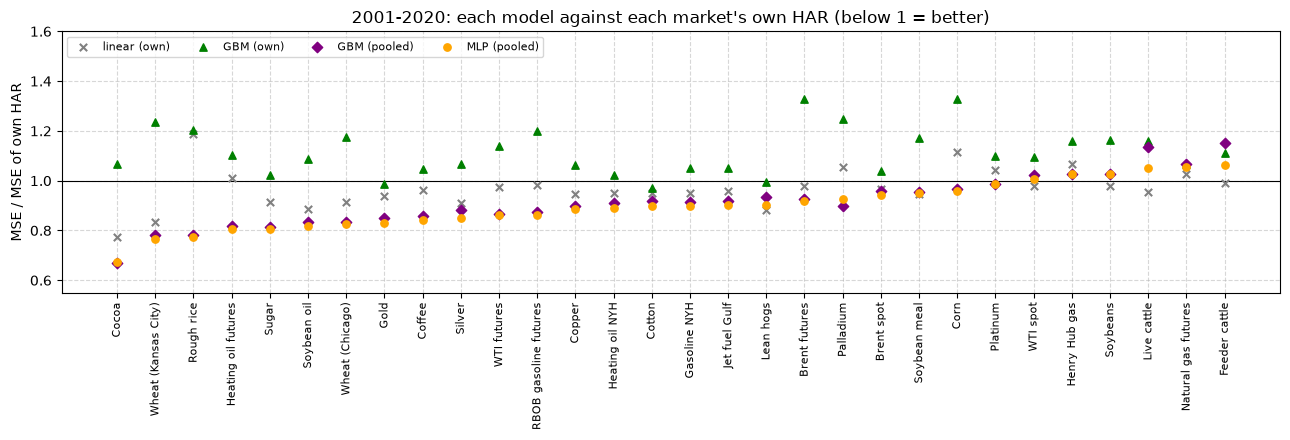

2001-2020                                                        2021-2026                                                    
                       linear (own) linear (pooled) GBM (own) GBM (pooled) MLP (pooled) linear (own) linear (pooled) GBM (own) GBM (pooled) MLP (pooled)
Crude oil                     0.977           0.974     1.118        0.944        0.929        1.094           1.005     1.053        0.976        0.949
Grains & oilseeds             0.946           0.847     1.175        0.836        0.826        0.959           1.011     1.046        1.039        1.006
Livestock                     0.953           1.106     1.113        1.134        1.053        0.950           1.115     0.957        1.002        0.971
Metals                        0.948           0.884     1.067        0.898        0.887        0.882           0.925     1.016        0.907        0.894
Refined products & gas        0.984           0.936     1.069        0.916        0.900        1.034           1.017     1.040        0.979        0.955
Softs                         0.933           0.839     1.036        0.836        0.826        0.886           0.950     0.966        0.952        0.949

In [9]:
models = ["linear (own)", "linear (pooled)", "GBM (own)", "GBM (pooled)", "MLP (pooled)"]
ratios = {
    period: pd.DataFrame({m: per_market(f(P), m)["MSE ratio"] for m in models})
    for period, f in PERIODS.items()
}

r_in_sample = ratios["2001-2020"].sort_values("MLP (pooled)")
fig, ax = plt.subplots(figsize=(13, 4.5))
for m, color, marker in [
    ("linear (own)", "grey", "x"),
    ("GBM (own)", "green", "^"),
    ("GBM (pooled)", "purple", "D"),
    ("MLP (pooled)", "orange", "o"),
]:
    ax.scatter(
        range(len(r_in_sample)), r_in_sample[m], color=color, marker=marker, s=28, label=m, zorder=3
    )
ax.axhline(1, color="black", lw=0.8)
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_xticks(range(len(r_in_sample)))
ax.set_xticklabels(r_in_sample.index, rotation=90, fontsize=8)
ax.set_ylabel("MSE / MSE of own HAR")
ax.set_ylim(0.55, 1.6)
ax.legend(ncol=4, fontsize=8, loc="upper left")
ax.set_title("2001-2020: each model against each market's own HAR (below 1 = better)")
plt.tight_layout()
plt.show()

pd.concat(
    {p: r.groupby(r.index.map(ASSET_CLASS)).median() for p, r in ratios.items()}, axis=1
).round(3)

Before 2021, pooled models win in most markets. The network and the trees both beat HAR in 80 % of markets, with median
ratios of 0.90 and 0.91. The same trees fitted to each market lose in 90 % of markets (median 1.10), because one market
is too small for a flexible model.

After 2020, only the network is significant. It wins in 73 % of markets (p = 0.008), against 57 % for the pooled trees
(p = 0.29) and 43 % for the pooled linear model. Livestock gains little from pooling. The network is worse than HAR on
livestock before 2021 (1.05) and only 3 % better after (0.97).

In [10]:
def panel_t(df, a, b):
    g = df.dropna(subset=[a, b])
    gap = (g.y - g[b]) ** 2 - (g.y - g[a]) ** 2
    return dm_t(gap.groupby(level=0).mean().sort_index())


pairs = [
    ("MLP (pooled)", "HAR (own)"),
    ("GBM (pooled)", "HAR (own)"),
    ("MLP (pooled)", "linear (pooled)"),
    ("MLP (pooled)", "linear (own)"),
]
table = {}
for a, b in pairs:
    row = {}
    for period, f in PERIODS.items():
        pm = per_market(f(P), a, bench=b)
        row[(period, "markets won")] = f"{(pm['MSE ratio'] < 1).sum()}/{len(pm)}"
        row[(period, "DM t, all markets")] = round(panel_t(f(P), a, b), 1)
    table[f"{a} vs {b}"] = row
pd.DataFrame(table).T

2001-2020                     2021-2026                  
                                markets won DM t, all markets markets won DM t, all markets
MLP (pooled) vs HAR (own)             24/30               5.1       22/30               2.4
GBM (pooled) vs HAR (own)             24/30               4.2       17/30               1.0
MLP (pooled) vs linear (pooled)       22/30               1.8       24/30               2.3
MLP (pooled) vs linear (own)          23/30               4.3       16/30               1.4

In this table the loss gap is averaged across markets each day, so correlated markets count as a single series. The
network beats HAR in both periods (t = 5.1 and 2.4). After 2020 it also beats the pooled linear model in 24 of 30
markets (t = 2.3). It does not significantly beat a linear model fitted to each market after 2020, with 16 of 30
markets and t = 1.4.

### 4.2 Crude oil (WTI futures)

This section only scores one market, WTI futures. The models are the same as in §4.1 and the pooled models are still
trained on all 30 markets, but we only look at their forecasts for WTI. Each row of the tables is a model, and its MSE
ratio and DM t compare its WTI forecasts with the WTI HAR. We add a network trained on WTI alone, to compare pooling
with the strongest single-market model.

In [11]:
def compare(df, models, bench="HAR (own)"):
    g = df.dropna(subset=models + [bench])
    rows = {}
    for m in models:
        e_bench, e_model = (g.y - g[bench]) ** 2, (g.y - g[m]) ** 2
        rows[m] = {
            "MSE ratio": e_model.mean() / e_bench.mean(),
            "DM t": dm_t(e_bench - e_model),
        }
    print(f"{len(g)} days, {g.index.min().date()} -> {g.index.max().date()}")
    return pd.DataFrame(rows).T


oil = P[P.asset == OIL]
oil_models = [
    "linear (own)",
    "linear (pooled)",
    "GBM (own)",
    "MLP (own, oil only)",
    "GBM (pooled)",
    "MLP (pooled)",
]
for period, f in PERIODS.items():
    print(f"WTI futures, {period}:", end=" ")
    display(compare(f(oil), oil_models).round(3))

WTI futures, 2001-2020: 3831 days, 2005-01-03 -> 2020-12-31


,MSE ratio,DM t
linear (own),0.975,0.467
linear (pooled),0.897,1.820
GBM (own),1.139,-2.219
"MLP (own, oil only)",0.893,2.016
GBM (pooled),0.868,2.723
MLP (pooled),0.863,2.878


WTI futures, 2021-2026: 1354 days, 2021-01-04 -> 2026-08-28


,MSE ratio,DM t
linear (own),1.132,-1.479
linear (pooled),1.034,-0.596
GBM (own),1.150,-2.022
"MLP (own, oil only)",1.144,-1.507
GBM (pooled),1.003,-0.042
MLP (pooled),0.974,0.460


Over 2005-2020 the pooled trees and the pooled network cut the oil error by 13-14 % (t ≈ 3). A network trained on oil
alone also does well (11 %, t = 2.0), but trees fitted to oil alone are worse than HAR. Over 2021-2026 the pooled trees
and network tie with the oil HAR (0.97-1.00), while every oil-only model is 13-15 % worse.

### 4.3 What the pooled models learned

We look at real volatility spikes, defined as days when last month's volatility is at least 1.5 times its 6-month level.
We split them by the size of the price move in that month. For each group we compare the share of the spike still
present one month later in the data with the share forecast by HAR and by the pooled network. A share of 1 means the
spike is still fully there, and 0 means volatility is back to its usual level.

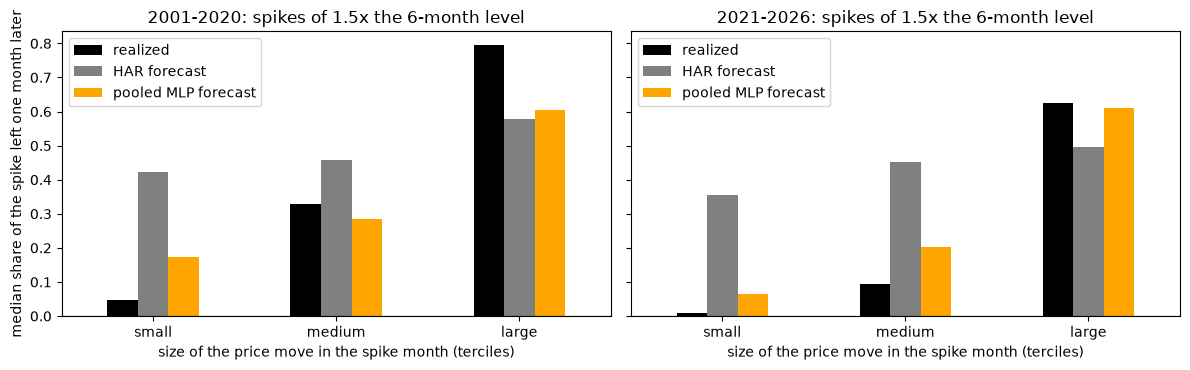

price move                     small  medium  large
2001-2020 realized              0.05    0.33   0.80
          HAR forecast          0.42    0.46   0.58
          pooled MLP forecast   0.17    0.28   0.60
2021-2026 realized              0.01    0.09   0.63
          HAR forecast          0.36    0.45   0.49
          pooled MLP forecast   0.06    0.20   0.61

spikes of 2x, 2001-2020: 578 market-days, 40 episodes in 20 markets, 292 market-days in February-June 2020


In [12]:
def spikes(df, ratio):
    shock = df.lrv_21 - df.lrv_126
    s = df[shock > np.log(ratio)].copy()
    s["shock"] = shock[shock > np.log(ratio)]
    s["price move"] = pd.qcut(s.ret_21.abs(), 3, labels=["small", "medium", "large"])
    return s


def share_remaining(s, col):
    return (s[col] - s.lrv_126) / s.shock


shares = {}
for period, f in PERIODS.items():
    s = spikes(f(P).dropna(subset=["HAR (own)", "MLP (pooled)"]), 1.5)
    for label, col in [
        ("realized", "y"),
        ("HAR forecast", "HAR (own)"),
        ("pooled MLP forecast", "MLP (pooled)"),
    ]:
        shares[(period, label)] = (
            share_remaining(s, col).groupby(s["price move"], observed=True).median()
        )
shares = pd.DataFrame(shares).T

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, period in zip(axes, PERIODS):
    shares.loc[period].T.plot.bar(ax=ax, rot=0, color=["black", "grey", "orange"])
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{period}: spikes of 1.5x the 6-month level")
    ax.set_xlabel("size of the price move in the spike month (terciles)")
axes[0].set_ylabel("median share of the spike left one month later")
plt.tight_layout()
plt.show()
display(shares.round(2))

big = spikes(in_sample(P), 2)
covid = (big.index >= "2020-02-15") & (big.index <= "2020-06-30")
episodes = sum(
    (g.index.to_series().diff() > pd.Timedelta(days=31)).sum() + 1 for _, g in big.groupby("asset")
)
print(
    f"spikes of 2x, 2001-2020: {len(big)} market-days, {episodes} episodes in {big.asset.nunique()} markets, "
    f"{covid.sum()} market-days in February-June 2020"
)

A spike lasts longer when prices moved. In the data, the share left rises from 0.05 after small moves to 0.80 after
large ones in 2001-2020, and from 0.01 to 0.63 in 2021-2026. HAR misses this, as it forecasts almost the same share in
every group (0.42 to 0.58 in 2001-2020). The network follows the data, with 0.17 after small moves and 0.60 after large
ones.

### 4.4 Economic value of the forecasts (risk targeting)

The position in each market is 10 % divided by the forecast volatility, capped at 5x, with costs of 2 bp. It is applied
the next day with the course's `compute_pnl`. A good forecast keeps realized risk close to 10 %, and the error is
$|\log(\text{realized}/\text{target})|$ per market-month.

The portfolio is the simple average of the 30 market strategies. Since each strategy targets the same 10 % risk,
each market carries about the same share of the portfolio's risk, even though the amounts invested differ (less in
volatile markets such as gas, more in calm ones such as gold).

The 30-market portfolio simulates positions in the 6 EIA spot prices. These positions could not be taken in practice,
because spot prices are not tradable and the EIA publishes them with a delay that the simulation ignores. We therefore
also report the 24 futures alone.

In [13]:
VT = ["HAR (own)", "GBM (pooled)", "MLP (pooled)"]


def risk_target_pnl(g, model, r, pred_lag=1):
    h = (RISK_TARGET / np.exp(g[model])).clip(upper=CAP).dropna()
    pnl = compute_pnl(h, r, pred_lag=pred_lag) - COST * h.diff().abs().shift(pred_lag)
    return pnl.loc[h.index].dropna()


def risk_error(model, pred_lag=1, markets=None):
    rows = []
    for asset, g in P.dropna(subset=VT).groupby("asset"):
        if markets is not None and asset not in markets:
            continue
        pnl = risk_target_pnl(g, model, ret[asset], pred_lag)
        monthly = pnl.groupby(pnl.index.to_period("M")).agg(["std", "size"])
        monthly = monthly[monthly["size"] >= 15]
        error = np.abs(np.log(monthly["std"] * np.sqrt(252) / RISK_TARGET))
        rows.append(
            pd.DataFrame({"asset": asset, "month": monthly.index, "error": error.to_numpy()})
        )
    return pd.concat(rows).set_index(["asset", "month"])["error"]


def risk_error_table(markets=None):
    errors = pd.DataFrame({m: risk_error(m, markets=markets) for m in VT}).dropna()
    is_in_sample = errors.index.get_level_values("month").year < START_OOS
    table = {}
    for period, mask in [("2001-2020", is_in_sample), ("2021-2026", ~is_in_sample)]:
        e = errors[mask]
        for m in VT:
            gap = (e["HAR (own)"] - e[m]).groupby(level="month").mean()
            table[(period, m)] = {
                "mean |log(realized / target)|": e[m].mean(),
                "months off by 1.5x or more, %": 100 * (e[m] > np.log(1.5)).mean(),
                "DM t": dm_t(gap, 3) if m != "HAR (own)" else np.nan,
            }
    return pd.DataFrame(table).T.round(3)


simulated = np.random.default_rng(0).standard_normal((200_000, 21))
print(
    f"error of a perfect forecast (21 Gaussian days): {np.abs(np.log(simulated.std(axis=1, ddof=1))).mean():.3f}"
)
futures_only = risk_error_table(FUTURES)["mean |log(realized / target)|"]
print(
    f"{len(FUTURES)} futures only, HAR vs pooled MLP:",
    ", ".join(
        f"{p} {futures_only[(p, 'HAR (own)')]:.3f} vs {futures_only[(p, 'MLP (pooled)')]:.3f}"
        for p in PERIODS
    ),
)
risk_error_table()

error of a perfect forecast (21 Gaussian days): 0.130


24 futures only, HAR vs pooled MLP: 2001-2020 0.202 vs 0.186, 2021-2026 0.184 vs 0.179


mean |log(realized / target)|  months off by 1.5x or more, %   DM t
2001-2020 HAR (own)                             0.199                         10.667    NaN
          GBM (pooled)                          0.187                          8.855  2.940
          MLP (pooled)                          0.187                          9.009  2.927
2021-2026 HAR (own)                             0.189                          8.873    NaN
          GBM (pooled)                          0.192                         10.343 -0.656
          MLP (pooled)                          0.189                          9.559 -0.130

Before 2021, pooled forecasts keep risk closer to the target, with an error of 0.187 against 0.199 for HAR (t = 2.9).
After 2020 there is no gain (0.189 for both, t = -0.1). Much of the error is noise, since even a perfect forecast would
score 0.13.

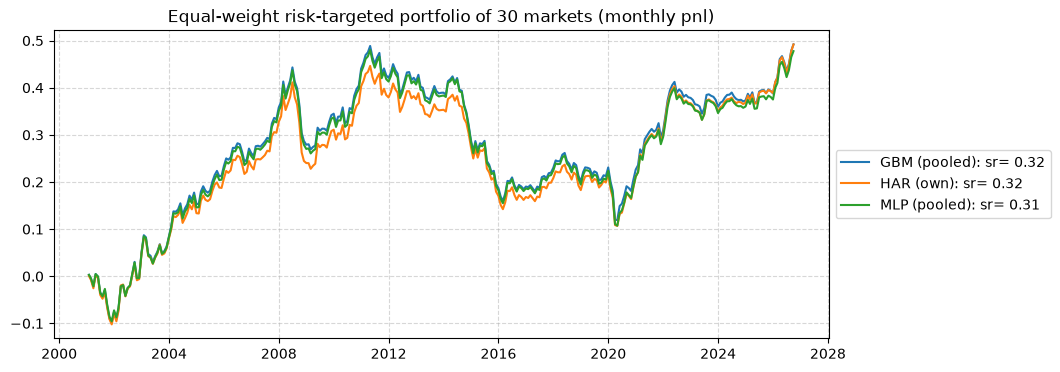

Sharpe ratio, 24 futures only: HAR (own) 0.25, GBM (pooled) 0.27, MLP (pooled) 0.28


,full sample,2001-2020,2021-2026
HAR (own),0.34,0.19,0.94
GBM (pooled),0.34,0.20,0.90
MLP (pooled),0.33,0.19,0.90


In [14]:
def portfolio(model, pred_lag=1, markets=None):
    pnls = {
        asset: risk_target_pnl(g, model, ret[asset], pred_lag)
        for asset, g in P.dropna(subset=VT).groupby("asset")
        if markets is None or asset in markets
    }
    return pd.concat(pnls, axis=1).mean(axis=1).dropna()


port = pd.DataFrame({m: portfolio(m) for m in VT}).dropna()
port_futures = pd.DataFrame({m: portfolio(m, markets=FUTURES) for m in VT}).dropna()
line(
    port.resample("ME").sum(),
    cumsum=True,
    figsize=(10, 4),
    title=f"Equal-weight risk-targeted portfolio of {P.asset.nunique()} markets (monthly pnl)",
)
plt.show()

print(
    f"Sharpe ratio, {len(FUTURES)} futures only:",
    ", ".join(
        f"{m} {sharpe_ratio(port_futures[m], num_period_per_year=252, remove_zeros=False):.2f}"
        for m in VT
    ),
)
pd.DataFrame(
    {
        period: {m: sharpe_ratio(x[m], num_period_per_year=252, remove_zeros=False) for m in VT}
        for period, x in [
            ("full sample", port),
            ("2001-2020", port[:"2020"]),
            ("2021-2026", port["2021":]),
        ]
    }
).round(2)

The Sharpe ratio is 0.33-0.34 with every forecast, and most of it comes from 2021-2026, when commodities rose. On the
24 futures it is 0.25-0.28. The forecasts control risk, but they do not create return.

In [15]:
def rolling_risk_bias(model, f):
    out = []
    for asset, g in P.dropna(subset=VT).groupby("asset"):
        z = f((ret[asset].reindex(g.index).shift(-1) / (np.exp(g[model]) / np.sqrt(252))).dropna())
        if len(z) > 252:
            out.append((z.rolling(252).std() - 1).abs().rename(asset))
    return pd.concat(out, axis=1).mean(axis=1)


for period, f in PERIODS.items():
    bias = {m: rolling_risk_bias(m, f) for m in ["HAR (own)", "MLP (pooled)"]}
    t = dm_t((bias["HAR (own)"] - bias["MLP (pooled)"]).dropna(), 252)
    print(
        f"risk bias, mean |rolling 1-year bias|, {period}: HAR {bias['HAR (own)'].mean():.3f}, "
        f"pooled MLP {bias['MLP (pooled)'].mean():.3f} (t = {t:.1f})"
    )

trading = {}
for m in VT:
    holding, turnover, at_cap = [], [], []
    for asset, g in P.dropna(subset=VT).groupby("asset"):
        h = (RISK_TARGET / np.exp(g[m])).clip(upper=CAP).dropna()
        holding.append(average_holding_period(h))
        turnover.append(h.diff().abs().mean() * 252)
        at_cap.append((h >= CAP).mean())
    trading[m] = {
        "holding period, days": np.median(holding),
        "turnover per year": np.median(turnover),
        "cost per year, %": 100 * COST * np.median(turnover),
        "days at the cap, %": 100 * np.mean(at_cap),
    }
pd.DataFrame(trading).T.round(2)

risk bias, mean |rolling 1-year bias|, 2001-2020: HAR 0.123, pooled MLP 0.080 (t = 6.0)
risk bias, mean |rolling 1-year bias|, 2021-2026: HAR 0.127, pooled MLP 0.105 (t = 3.0)


,"holding period, days",turnover per year,"cost per year, %","days at the cap, %"
HAR (own),59.49,2.93,0.06,0.0
GBM (pooled),58.54,3.17,0.06,0.0
MLP (pooled),56.88,3.26,0.07,0.0


The risk bias also favours the pooled network in both periods, with 0.080 against 0.123 for HAR before
2021 (t = 6.0) and 0.105 against 0.127 after (t = 3.0). The measure is $\text{Std}[r_{t+1}/\hat\sigma_t] - 1$, from
`20_Measuring_risk`. Costs are negligible. Positions are held 57-59 days, costs are 0.06-0.07 % of the position a year,
and the cap is never reached.

## 5. Robustness

We used the robustness checks lead-lag (`11_Backtesting`), off-the-top (`11_Backtesting`), hyperparameter sensitivity
(`19_Hyperparameter_optimisation`), seed stability (`16_Trees_Neural_nets`) and non-normality (`23_Non_normality`)
from the course.

### 5.1 Lead-lag test for look-ahead

We shift the positions in time. Lag 0 is the tradable strategy, negative lags use forecasts that would only be known
later, and positive lags use stale forecasts.

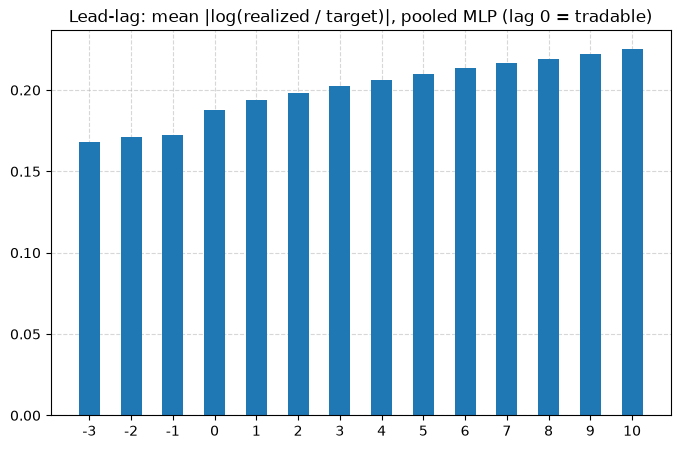

,-3,-2,-1,0,1,2,3,4,5,6,7,8,9,10
risk error,0.168,0.171,0.172,0.188,0.194,0.198,0.202,0.206,0.21,0.213,0.217,0.219,0.222,0.225


In [16]:
lead_lag = pd.Series({i: risk_error("MLP (pooled)", pred_lag=1 + i).mean() for i in range(-3, 11)})
bar(
    lead_lag,
    sort=False,
    title="Lead-lag: mean |log(realized / target)|, pooled MLP (lag 0 = tradable)",
)
plt.show()
lead_lag.round(3).to_frame("risk error").T

There is no sign of look-ahead bias. At lag 0 the error is 0.188, while a look-ahead of only one day would give 0.172.
The information decays within weeks, and the error rises steadily to 0.225 after 10 days.

### 5.2 Feature importance (feature off-the-top, pooled trees, 2001-2020)

Each column removes one feature and re-runs the whole walk-forward, with the tree setting chosen most often by the tuning.

In [17]:
tuned = [e.model_.best_params_ for e in walk_forwards["GBM (pooled)"].estimators_]
most_common = max(tuned, key=tuned.count)
gbm_fixed = clone(GBM).set_params(**most_common)


def gbm_without(cols):
    walk = WalkForward(
        Pooled(gbm_fixed, cols=tuple(cols)), cv=CalendarWalkForward(last=START_OOS - 1)
    )
    P["_x"] = walk.compute_predictions(features, target, n_jobs=-1).pred_.to_numpy()
    return per_market(in_sample(P), "_x")["MSE ratio"].median()


removed = {"none": []} | {c: [c] for c in FEATURES} | {"ret_21 and ret_5": ["ret_21", "ret_5"]}
off_the_top = pd.Series(
    {k: gbm_without([c for c in FEATURES if c not in v]) for k, v in removed.items()}
)
P = P.drop(columns="_x")
off_the_top.round(3).to_frame("median MSE ratio, feature removed").T

,none,lrv_1,lrv_5,lrv_21,lrv_63,lrv_126,lrv_dn_21,ret_21,ret_5,ret_21 and ret_5
"median MSE ratio, feature removed",0.911,0.914,0.928,0.92,0.911,0.913,0.909,0.936,0.909,0.937


Without the two past-return features, the median ratio rises from 0.911 to 0.937, so the trees lose a large part of
their gain over HAR. This corresponds to the price-move rule of §4.3. Among the volatility features, removing the 5-day
or the 21-day volatility raises the ratio to 0.928 and 0.920. Removing any other feature changes it by 0.003 or less,
which is noise.

### 5.3 Market importance (market off-the-top)

We remove one class from the network's training pool and re-run the walk-forward. The last two columns score the
removed markets, which the network then never saw.

In [18]:
def mlp_walk(markets=None, **kwargs):
    walk = WalkForward(Pooled(mlp_ensemble(**kwargs), markets=markets), cv=CalendarWalkForward())
    return walk.compute_predictions(features, target, n_jobs=1).pred_.to_numpy()


def gbm_walk(**params):
    walk = WalkForward(Pooled(clone(GBM).set_params(**params)), cv=CalendarWalkForward())
    return walk.compute_predictions(features, target, n_jobs=-1).pred_.to_numpy()


def score(col):
    out = {}
    for period, f in PERIODS.items():
        pm = per_market(f(P), col)
        out[(period, "median MSE ratio")] = pm["MSE ratio"].median()
        out[(period, "markets won")] = (pm["MSE ratio"] < 1).sum()
    return out


def cached_table(name, compute):
    path = CACHE_DIR / f"{name}_{fingerprint}{'_fast' if FAST else ''}.pkl"
    if path.exists() and not FORCE_RECOMPUTE:
        return pd.read_pickle(path)
    table = compute()
    table.to_pickle(path)
    return table


def market_off_the_top():
    out = {}
    for c, names in CLASSES.items():
        P["_x"] = mlp_walk(markets=[a for a in ret if a not in names])
        row = score("_x")
        for period, f in PERIODS.items():
            row[(period, "removed markets alone")] = (
                per_market(f(P), "_x").loc[names, "MSE ratio"].median()
            )
        out[f"without {c}"] = row
    P.drop(columns="_x", inplace=True)
    return pd.DataFrame(out).T


WON = {(period, "markets won"): int for period in PERIODS}
markets_removed = cached_table("v4_market_off_the_top", market_off_the_top).astype(WON)
markets_removed[
    [
        ("2021-2026", "median MSE ratio"),
        ("2021-2026", "markets won"),
        ("2001-2020", "removed markets alone"),
        ("2021-2026", "removed markets alone"),
    ]
].round(3)

2021-2026                         2001-2020             2021-2026
                               median MSE ratio markets won removed markets alone removed markets alone
without Crude oil                         0.950          23                 0.940                 0.952
without Refined products & gas            0.974          19                 0.900                 1.031
without Metals                            0.963          22                 0.882                 0.896
without Grains & oilseeds                 0.954          18                 0.850                 1.022
without Softs                             0.958          21                 0.846                 0.959
without Livestock                         0.948          20                 1.210                 1.157

No single class carries the result. The gain comes from the pool as a whole, not from one class. Whichever class is
removed, 18-23 of 30 markets still beat HAR after 2020. After 2020, metals (0.90), softs
(0.96) and crude oil (0.95) still beat HAR when the network never saw them in training, almost as well as when they are in the training pool (0.89,
0.95 and 0.95). Grains (1.02), refined products (1.03) and livestock (1.16) do not.

### 5.4 Hyperparameters, seeds and fat tails

In [19]:
print(
    f"tuned tree setting {most_common} chosen in {tuned.count(most_common)} of {len(tuned)} splits"
)

tuned tree setting {'max_iter': 150, 'max_leaf_nodes': 15, 'min_samples_leaf': 1000} chosen in 11 of 13 splits


In [20]:
VARIANTS = {
    "MLP (64, 32), baseline": lambda: P["MLP (pooled)"].to_numpy(),
    "MLP (32,)": lambda: mlp_walk(hidden=(32,)),
    "MLP (16, 8)": lambda: mlp_walk(hidden=(16, 8)),
    "MLP (128, 64)": lambda: mlp_walk(hidden=(128, 64)),
    "MLP, L2 penalty 0.01": lambda: mlp_walk(alpha=1e-2),
    "MLP, L2 penalty 1": lambda: mlp_walk(alpha=1.0),
}
for iterations in [150, 400]:
    for leaves in [15, 63]:
        for leaf_size in [200, 1000]:
            VARIANTS[f"GBM, {iterations} iterations, {leaves} leaves, min leaf {leaf_size}"] = (
                lambda i=iterations, l=leaves, s=leaf_size: gbm_walk(
                    max_iter=i, max_leaf_nodes=l, min_samples_leaf=s
                )
            )


def sensitivity():
    out = {}
    for name, run in VARIANTS.items():
        P["_x"] = run()
        out[name] = score("_x")
    P.drop(columns="_x", inplace=True)
    return pd.DataFrame(out).T


cached_table("v4_sensitivity", sensitivity).astype(WON).round(3)

2001-2020                    2021-2026            
                                              median MSE ratio markets won median MSE ratio markets won
MLP (64, 32), baseline                                   0.898          24            0.957          22
MLP (32,)                                                0.886          25            0.960          22
MLP (16, 8)                                              0.883          25            0.961          22
MLP (128, 64)                                            0.897          24            0.963          22
MLP, L2 penalty 0.01                                     0.899          24            0.956          22
MLP, L2 penalty 1                                        0.897          25            0.966          22
GBM, 150 iterations, 15 leaves, min leaf 200             0.910          23            0.969          17
GBM, 150 iterations, 15 leaves, min leaf 1000            0.911          24            0.972          17
GBM, 150 iterations, 63 leaves, min leaf 200             0.936          21            0.979          18
GBM, 150 iterations, 63 leaves, min leaf 1000            0.915          24            0.977          17
GBM, 400 iterations, 15 leaves, min leaf 200             0.924          23            0.970          18
GBM, 400 iterations, 15 leaves, min leaf 1000            0.918          23            0.976          19
GBM, 400 iterations, 63 leaves, min leaf 200             0.973          18            1.010          14
GBM, 400 iterations, 63 leaves, min leaf 1000            0.943          20            0.994          16

In [21]:
splits = list(CalendarWalkForward().split(features))
single = {}
for j, seed in enumerate(SEEDS):
    h = np.full(len(P), np.nan)
    for (_, test), fitted in zip(splits, walk_forwards["MLP (pooled)"].estimators_):
        ensemble = fitted.model_
        network = ensemble.regressor_.estimators_[j]
        pred = network.predict(features.iloc[test][FEATURES])
        h[test] = ensemble.transformer_.inverse_transform(pred.reshape(-1, 1)).ravel()
    P["_x"] = h
    single[seed] = score("_x")
P = P.drop(columns="_x")
single = pd.DataFrame(single).T
won = single[("2021-2026", "markets won")].astype(int)
print(
    f"single networks, 2021-2026: markets won {won.min()}-{won.max()} (mean {won.mean():.1f}); "
    f"the average of the {len(SEEDS)} networks wins in {score('MLP (pooled)')[('2021-2026', 'markets won')]}"
)

single networks, 2021-2026: markets won 19-23 (mean 21.3); the average of the 10 networks wins in 22


In [22]:
x = port["MLP (pooled)"]
sr = x.mean() / x.std()
n, sk, ku = len(x), skew(x), kurtosis(x)
print(
    f"pooled MLP portfolio: skewness {sk:.2f}, excess kurtosis {ku:.2f}, Jarque-Bera p-value {jarque_bera(x)[1]:.1e}"
)
print(
    f"Sharpe {sharpe_ratio(x, num_period_per_year=252, remove_zeros=False):.2f}, standard error "
    f"{np.sqrt((1 + 0.5 * sr**2) / n * 252):.2f} (Lo) and "
    f"{np.sqrt((1 + 0.5 * sr**2 - sk * sr + 0.25 * ku * sr**2) / n * 252):.2f} (Mertens)"
)
print(f"total runtime {(time.time() - start_time) / 60:.0f} min")

pooled MLP portfolio: skewness -0.43, excess kurtosis 2.51, Jarque-Bera p-value 0.0e+00
Sharpe 0.33, standard error 0.20 (Lo) and 0.20 (Mertens)
total runtime 10 min


The tuning is stable. The same tree setting, the most regularized corner of the grid, is chosen in 11 of 13 splits. The
network does not depend much on its architecture, with medians of 0.883-0.899 before 2021 and 0.956-0.966 after, and 22
markets won after 2020 in every case. The trees are more sensitive (0.969-1.010 after 2020, 14-19 markets).

The result does not depend on the seed either. A single network wins in 19-23 markets after 2020, and since the sign
test needs 20, the weakest network falls just short of it. Fat tails make the Sharpe ratio imprecise. Portfolio returns
have an excess kurtosis of 2.5 (Jarque-Bera p ≈ 0), and the Sharpe standard error is 0.20, larger than any gap between
forecasts.

## 6. Conclusion

One pooled model forecasts commodity volatility better than a HAR fitted to each market. The pooled network wins in
80 % of markets before 2021 and in 73 % after, and the result holds when all markets are treated as one series
(t = 5.1 and 2.4). It works because one market has too few volatility episodes for a flexible model, while 30 markets
have enough. The rule the network learns is simple and can be seen in the raw data. After a spike, a large price move
makes it last. The forecasts improve risk control before 2021 and the risk bias in both periods, but they do not raise
the Sharpe ratio.

Checked against the validation steps of the course, the economic rationale is supported, with more episodes per model
and a rule visible in raw data. Predictability is supported too, with 80 % and 73 % of markets and a panel t of 5.1 and
2.4, although the gain is smaller after 2020. The robustness checks (lead-lag, removed features and classes,
architectures, seeds) hold for the network and less for the trees. Turnover is low and costs are negligible, but the
Sharpe ratio is the same, so the value lies in risk control.

### Limits

* Henry Hub before 2012. The current EIA file has gaps of several weeks before 2012, so this series starts in 2012. With
  the complete 1997-2011 history of this market, the result before 2021 still holds (t = 4.5 instead of 5.1).
* Strongest simple rival. After 2020 the network beats a linear model fitted to each market in 16 of 30 markets, without
  significance (t = 1.4). The study also has no GARCH benchmark.
* Crude oil after 2020. The pooled trees and network only tie with the oil HAR (0.97-1.00).
* Few large episodes. Spikes of twice the 6-month level form 40 episodes in 20 markets, and half of their days fall in
  February-June 2020, so the rule is estimated on few independent events.
* Noisy target. Volatility is measured from 21 daily returns. Even a perfect forecast would miss the 10 % target by 0.13
  on average, which limits any measured gain.
* Correlated markets. The sign test counts 30 markets as independent. The panel test corrects the mean loss but not the
  count, and the single-market tests are not corrected for multiple testing.
* Data. Before 2009 the pool is mostly energy (87 % of the first split), and EIA spot prices are not tradable. The
  ±25 % clip binds on 96 days, almost all in energy, so energy tails are understated.

## References

* Christensen, K., Siggaard, M. & Veliyev, B. (2023). A machine learning approach to volatility forecasting. *Journal of
  Financial Econometrics*, 21(5), 1680-1727. https://doi.org/10.1093/jjfinec/nbac020
* Corsi, F. (2009). A simple approximate long-memory model of realized volatility. *Journal of Financial Econometrics*,
  7(2), 174-196. https://doi.org/10.1093/jjfinec/nbp001
* Diebold, F. X. & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*,
  13(3), 253-263. https://doi.org/10.1080/07350015.1995.10524599
* Gu, S., Kelly, B. & Xiu, D. (2020). Empirical asset pricing via machine learning. *Review of Financial Studies*, 33(5),
  2223-2273. https://doi.org/10.1093/rfs/hhaa009
* Lo, A. W. (2002). The statistics of Sharpe ratios. *Financial Analysts Journal*, 58(4), 36-52.
  https://doi.org/10.2469/faj.v58.n4.2453
* Newey, W. K. & West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent
  covariance matrix. *Econometrica*, 55(3), 703-708. https://doi.org/10.2307/1913610
* Sirignano, J. & Cont, R. (2019). Universal features of price formation in financial markets: perspectives from deep
  learning. *Quantitative Finance*, 19(9), 1449-1459. https://doi.org/10.1080/14697688.2019.1622295
* Zhang, C., Zhang, Y., Cucuringu, M. & Qian, Z. (2024). Volatility forecasting with machine learning and intraday
  commonality. *Journal of Financial Econometrics*, 22(2), 492-530. https://doi.org/10.1093/jjfinec/nbad005
* Champonnois, S. Course *Machine learning for portfolio management and trading*. https://github.com/schampon/skfin
* DataCamp. *Machine Learning with Tree-Based Models in Python* (KU Leuven data science course).
* DataCamp. *Nonlinear Modeling with Generalized Additive Models (GAMs) in Python* (KU Leuven data science course).

## AI assistance

We did the research and chose the research question. We designed the architecture of the study from the literature,
from courses we followed at KU Leuven (Belgium) and from this course, and we chose the parts of code to reuse from the
course's GitHub repository. We then asked Claude (Sonnet 5.5) to apply the plan we had
written. Claude wrote the code. We wrote all the explanations, and Claude translated them into English and edited
their wording.

Claude also helped with the use of HAC (Newey-West) standard errors and the 42-day gap. It gave the idea of removing
roll days and pointed out that the sign test counts correlated markets as independent series. It refined
the code structure and efficiency, helped clean our data and audited the notebook (see 6. Limits). The prompts and plans we used can be shared on request.
